# ICU Patient Data — Exploratory Analysis

This notebook explores the synthetic ICU monitoring dataset (`icu_data.csv`).
The data covers **20 patients** over a **30-minute monitoring window**,
with one measurement per minute per patient (600 rows total).

Each row contains:
| Column | Description |
|---|---|
| PID | Patient identifier (P + 4-digit number) |
| BID | ICU bed identifier |
| MID | ICU machine identifier |
| TS | Timestamp (YYYY-MM-DD HH:MM:SS) |
| SBP | Systolic blood pressure (mmHg) |
| DBP | Diastolic blood pressure (mmHg) |
| HR | Heart rate (bpm) |
| Fluids | IV fluid rate (ml/min) |
| BloodLost | Blood loss rate (ml/min) |
| BloodGiven | Blood transfusion rate (ml/min) |

---

## Setup — imports and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path

# Consistent plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.0)
plt.rcParams['figure.dpi'] = 110

# Load data — path is relative to the notebook location (bp1/notebooks/)
data_path = Path('..') / 'data' / 'icu_data.csv'
df = pd.read_csv(data_path, parse_dates=['TS'])

# Add a 'minute' column (0-29) relative to each patient's monitoring start
df['minute'] = df.groupby('PID').cumcount()

print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

Shape: (600, 11)
Columns: ['PID', 'BID', 'MID', 'TS', 'SBP', 'DBP', 'HR', 'Fluids', 'BloodLost', 'BloodGiven', 'minute']


,PID,BID,MID,TS,SBP,DBP,HR,Fluids,BloodLost,BloodGiven,minute
0,P13847,B01,M20,2026-05-11 08:00:00,115.6,63.5,95.7,2.09,1.37,0.00,0
1,P13847,B01,M20,2026-05-11 08:01:00,113.3,62.9,98.0,2.14,1.16,0.00,1
2,P13847,B01,M20,2026-05-11 08:02:00,112.9,64.7,99.0,2.12,1.03,1.38,2
3,P13847,B01,M20,2026-05-11 08:03:00,114.0,64.7,99.8,2.22,1.38,1.70,3
4,P13847,B01,M20,2026-05-11 08:04:00,111.0,65.8,98.5,2.14,1.37,1.29,4


---
## 1. Dataset Overview

In [2]:
n_patients = df['PID'].nunique()
n_rows     = len(df)
rows_per_patient = df.groupby('PID').size()

print(f'Number of patients      : {n_patients}')
print(f'Total measurement rows  : {n_rows}')
print(f'Rows per patient        : {rows_per_patient.unique().tolist()} (all equal)')
print(f'Monitoring window       : {rows_per_patient.unique()[0]} minutes per patient')

no_blood = df.groupby('PID')['BloodLost'].max() == 0
print(f'\nPatients with no blood loss: {no_blood.sum()} '
      f'({no_blood.sum()/n_patients*100:.0f}%)')
print(f'  PIDs: {sorted(no_blood[no_blood].index.tolist())}')

# Unique beds and machines
bed_assignments = df.groupby('PID')['BID'].first().reset_index()
mac_assignments = df.groupby('PID')['MID'].first().reset_index()
combined = bed_assignments.merge(mac_assignments, on='PID')
print(f'\nBed and machine assignments:')
print(combined.to_string(index=False))

Number of patients      : 20
Total measurement rows  : 600
Rows per patient        : [30] (all equal)
Monitoring window       : 30 minutes per patient

Patients with no blood loss: 2 (10%)
  PIDs: ['P14102', 'P15463']

Bed and machine assignments:
  PID BID MID
P11256 B18 M17
P11729 B19 M04
P11893 B08 M18
P12516 B10 M14
P12673 B06 M13
P13091 B14 M03
P13615 B07 M02
P13847 B01 M20
P14102 B05 M19
P14538 B02 M06
P15024 B11 M12
P15463 B17 M07
P16184 B12 M15
P16758 B13 M09
P17291 B16 M16
P17824 B03 M10
P18350 B04 M08
P18436 B15 M01
P19012 B09 M05
P19347 B20 M11


---
## 2. Per-patient Descriptive Statistics

Mean, minimum, and maximum for each numerical parameter grouped by patient.
The wide range of values — especially for BP and HR — reflects the diversity of
diagnoses present in an ICU cohort.

In [3]:
vitals_cols = ['SBP', 'DBP', 'HR', 'Fluids', 'BloodLost', 'BloodGiven']

stats = (
    df.groupby('PID')[vitals_cols]
    .agg(['mean', 'min', 'max'])
    .round(2)
)

# Flatten multi-level column names for readability
stats.columns = [f'{col}_{agg}' for col, agg in stats.columns]
stats

,SBP_mean,SBP_min,SBP_max,DBP_mean,DBP_min,DBP_max,HR_mean,HR_min,HR_max,Fluids_mean,Fluids_min,Fluids_max,BloodLost_mean,BloodLost_min,BloodLost_max,BloodGiven_mean,BloodGiven_min,BloodGiven_max
PID,,,,,,,,,,,,,,,,,,
P11256,92.22,90.0,98.7,67.95,60.0,72.3,108.63,105.2,111.9,3.71,3.31,4.02,1.11,1.00,1.38,0.84,0.0,1.68
P11729,94.75,90.0,100.7,71.03,67.4,75.0,119.12,108.3,129.0,3.32,2.81,3.77,1.06,1.00,1.27,0.88,0.0,1.74
P11893,96.40,90.0,100.5,61.89,60.0,65.3,116.43,110.9,120.8,1.69,1.10,2.42,1.65,1.36,2.06,1.32,0.0,2.36
P12516,123.56,119.7,127.8,67.19,61.8,74.0,92.34,87.5,97.8,2.01,1.70,2.34,2.22,1.55,2.92,2.08,0.0,3.22
P12673,120.68,115.6,132.3,64.86,60.0,72.5,97.31,90.5,105.8,2.23,1.72,2.86,3.74,2.59,4.24,2.82,0.0,4.74
P13091,95.35,90.3,98.4,74.20,66.4,78.6,60.32,56.2,62.9,1.95,1.57,2.32,1.14,1.00,1.45,0.90,0.0,1.80
P13615,163.60,148.8,175.2,100.44,97.8,103.6,90.86,84.4,96.4,1.48,1.00,2.17,1.42,1.00,1.97,1.43,0.0,2.24
P13847,112.29,103.0,121.7,66.15,62.6,72.6,96.08,91.8,99.8,2.21,1.75,2.51,1.69,1.03,2.11,1.46,0.0,2.56
P14102,118.32,112.5,122.9,64.71,60.0,70.6,99.39,94.9,104.4,2.58,2.23,2.88,0.00,0.00,0.00,0.00,0.0,0.00


In [4]:
# Summary across the whole cohort
print('Cohort-wide summary statistics:')
df[vitals_cols].describe().round(2)

Cohort-wide summary statistics:


,SBP,DBP,HR,Fluids,BloodLost,BloodGiven
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,120.88,71.87,100.65,2.35,1.76,1.43
std,24.05,10.85,21.66,0.87,1.08,1.23
min,90.00,60.00,50.00,1.00,0.00,0.00
25%,99.48,63.28,88.10,1.76,1.07,0.00
50%,118.40,69.30,98.75,2.19,1.55,1.38
75%,128.05,76.10,117.18,2.79,2.41,2.07
max,175.20,103.60,138.50,4.72,4.98,4.83


---
## 3. Vital Sign Trends Over Time (per patient)

Each subplot shows SBP (red), DBP (blue) and HR (green) for one patient across
the 30-minute window.  
Patterns consistent with each underlying diagnosis are visible:
- Patients with **hypertensive crisis** (P13615) show markedly elevated BP.
- Patients in **septic / cardiogenic shock** (P11256, P19012) have low BP and high HR.
- The **TBI** patient (P14538) shows the Cushing reflex: high BP + low HR.

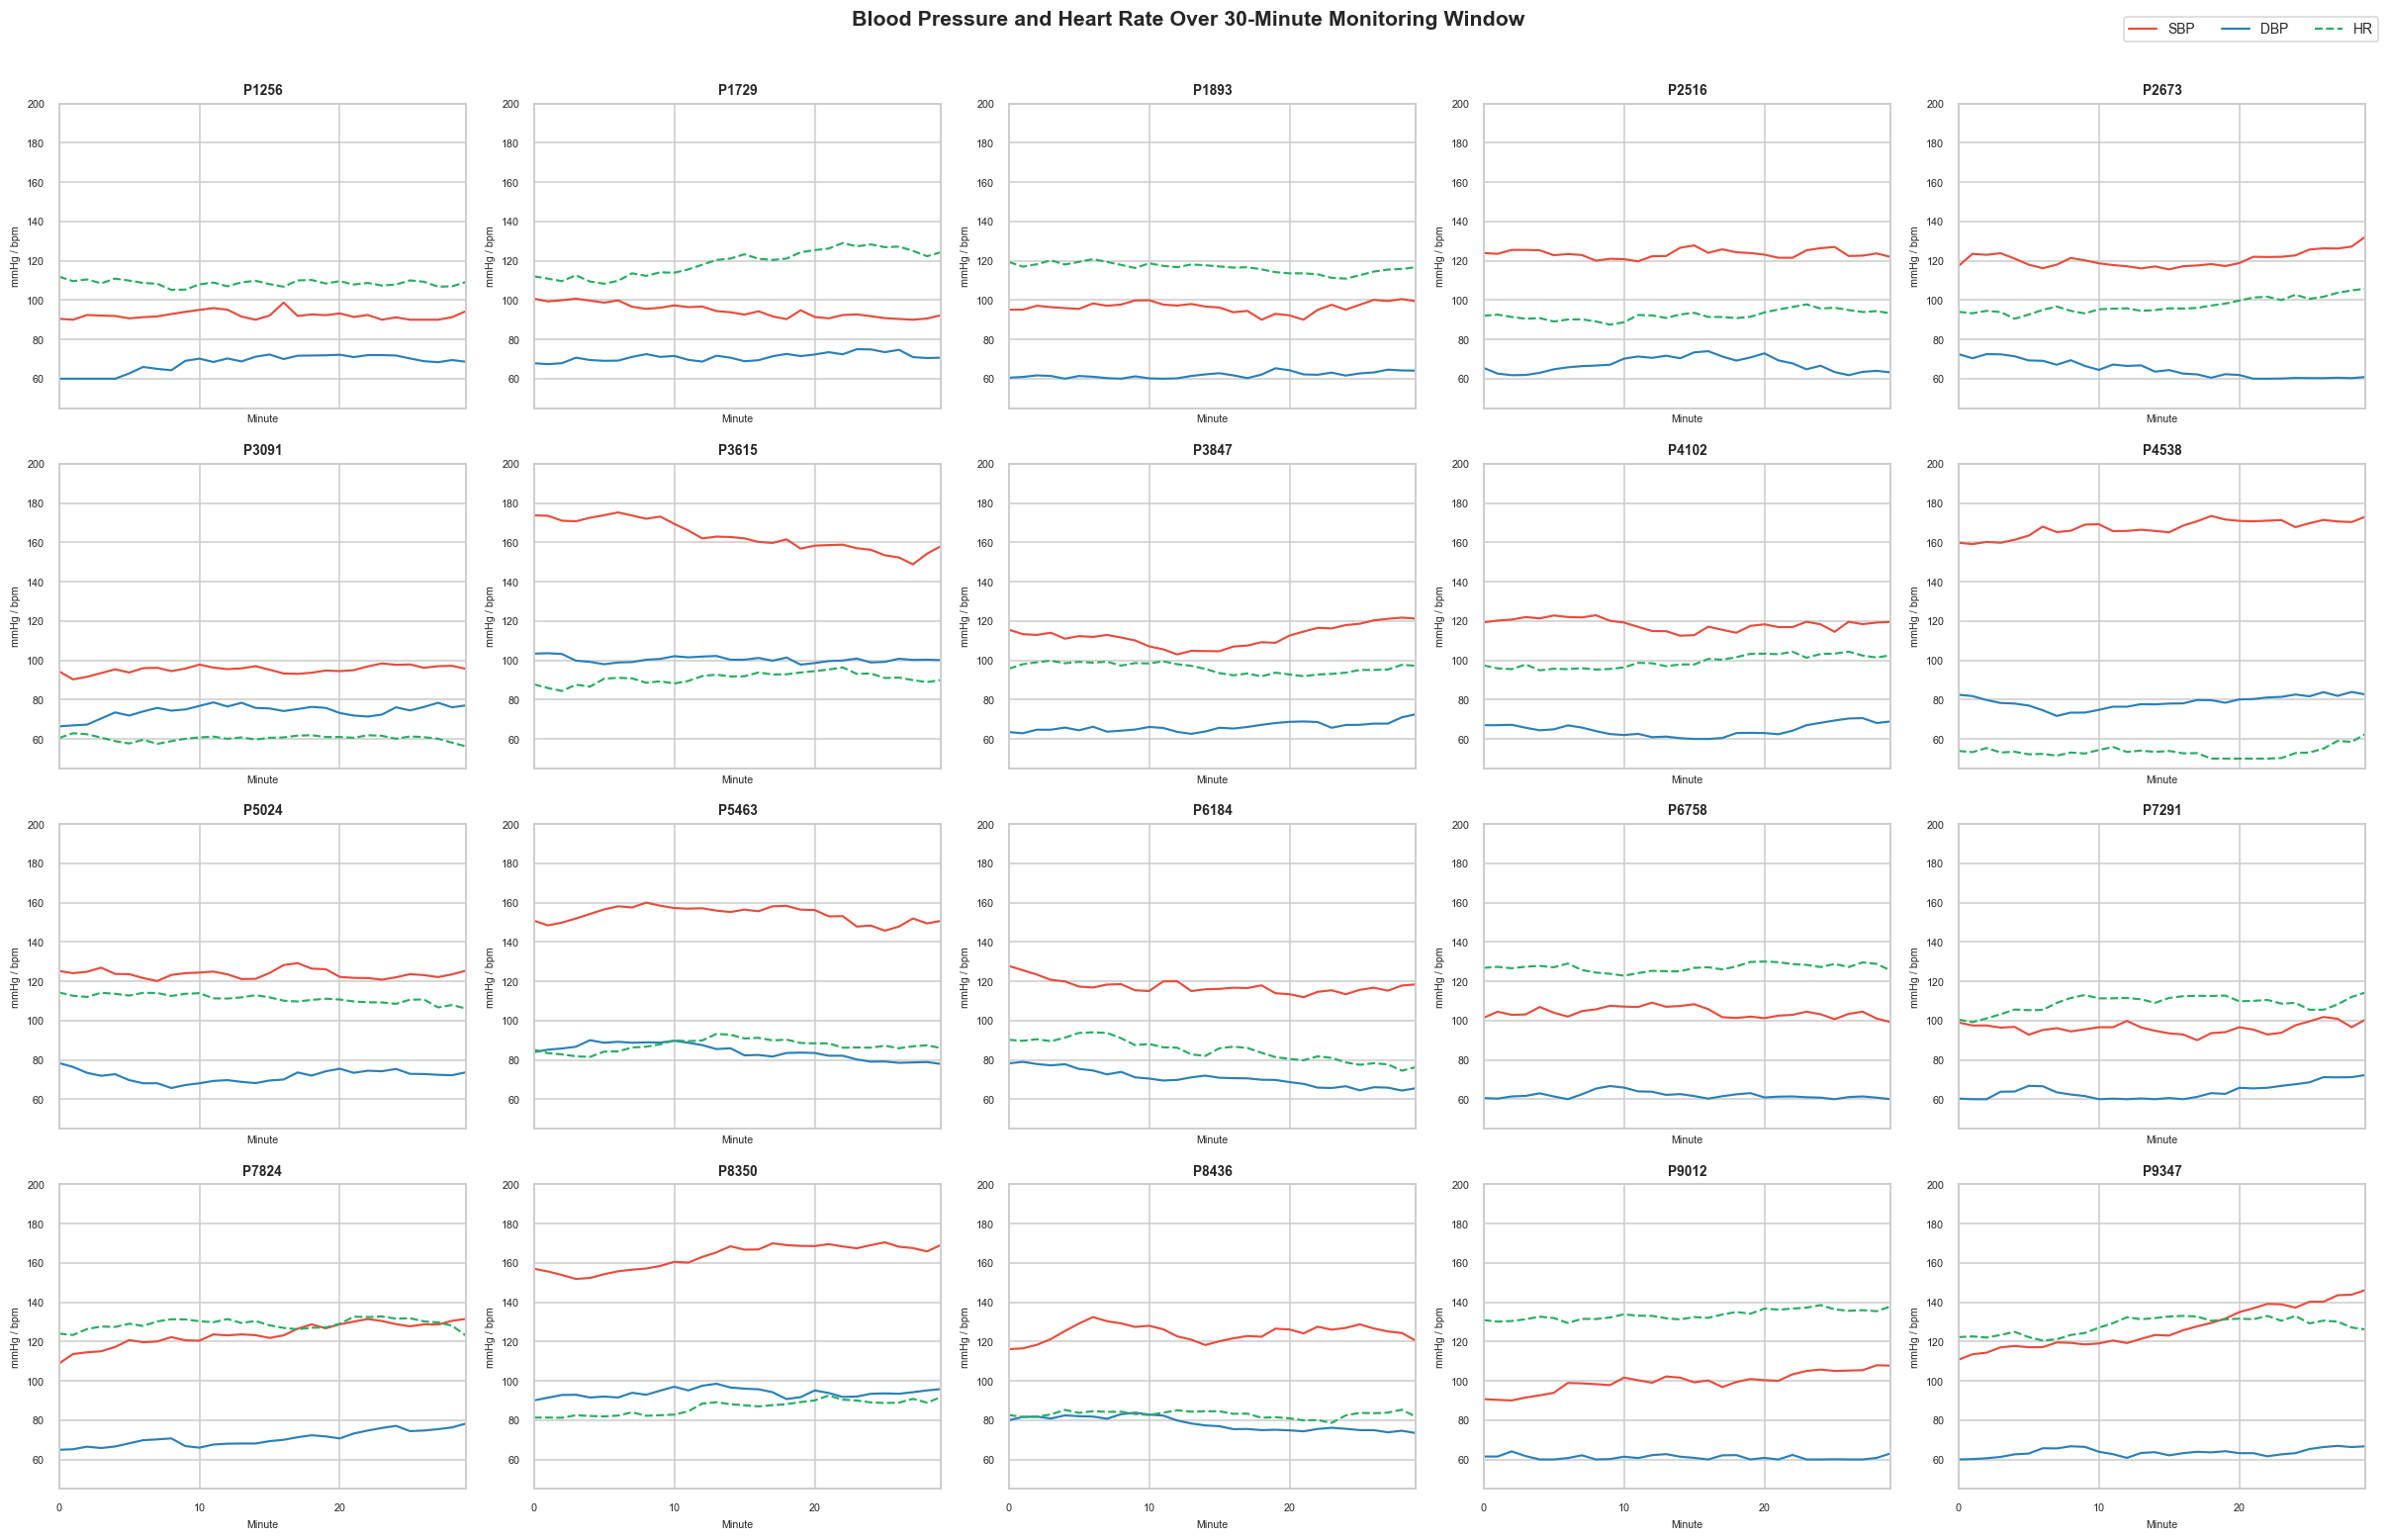

In [5]:
patients_sorted = sorted(df['PID'].unique())
n_cols = 5
n_rows_plot = 4  # 20 patients / 5 columns

fig, axes = plt.subplots(n_rows_plot, n_cols, figsize=(22, 14), sharex=True)
fig.suptitle('Blood Pressure and Heart Rate Over 30-Minute Monitoring Window',
             fontsize=14, fontweight='bold', y=1.01)

for idx, pid in enumerate(patients_sorted):
    ax  = axes[idx // n_cols, idx % n_cols]
    grp = df[df['PID'] == pid].sort_values('minute')

    ax.plot(grp['minute'], grp['SBP'], color='#e74c3c', lw=1.4, label='SBP')
    ax.plot(grp['minute'], grp['DBP'], color='#2980b9', lw=1.4, label='DBP')
    ax.plot(grp['minute'], grp['HR'],  color='#27ae60', lw=1.4, label='HR',  ls='--')

    ax.set_title(pid, fontsize=9, fontweight='bold')
    ax.set_ylim(45, 200)
    ax.set_xlim(0, 29)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.tick_params(labelsize=7)
    ax.set_ylabel('mmHg / bpm', fontsize=7)
    ax.set_xlabel('Minute', fontsize=7)

# Single shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=9, ncol=3,
           bbox_to_anchor=(1.0, 1.01))

plt.tight_layout()
plt.show()

---
## 4. Spread of Patient Averages Across the Cohort

Box plots show the **distribution of per-patient averages** for each parameter.
The spread in SBP and HR is particularly wide, reflecting the heterogeneity of
ICU diagnoses — from hypotensive shock patients to hypertensive emergencies.

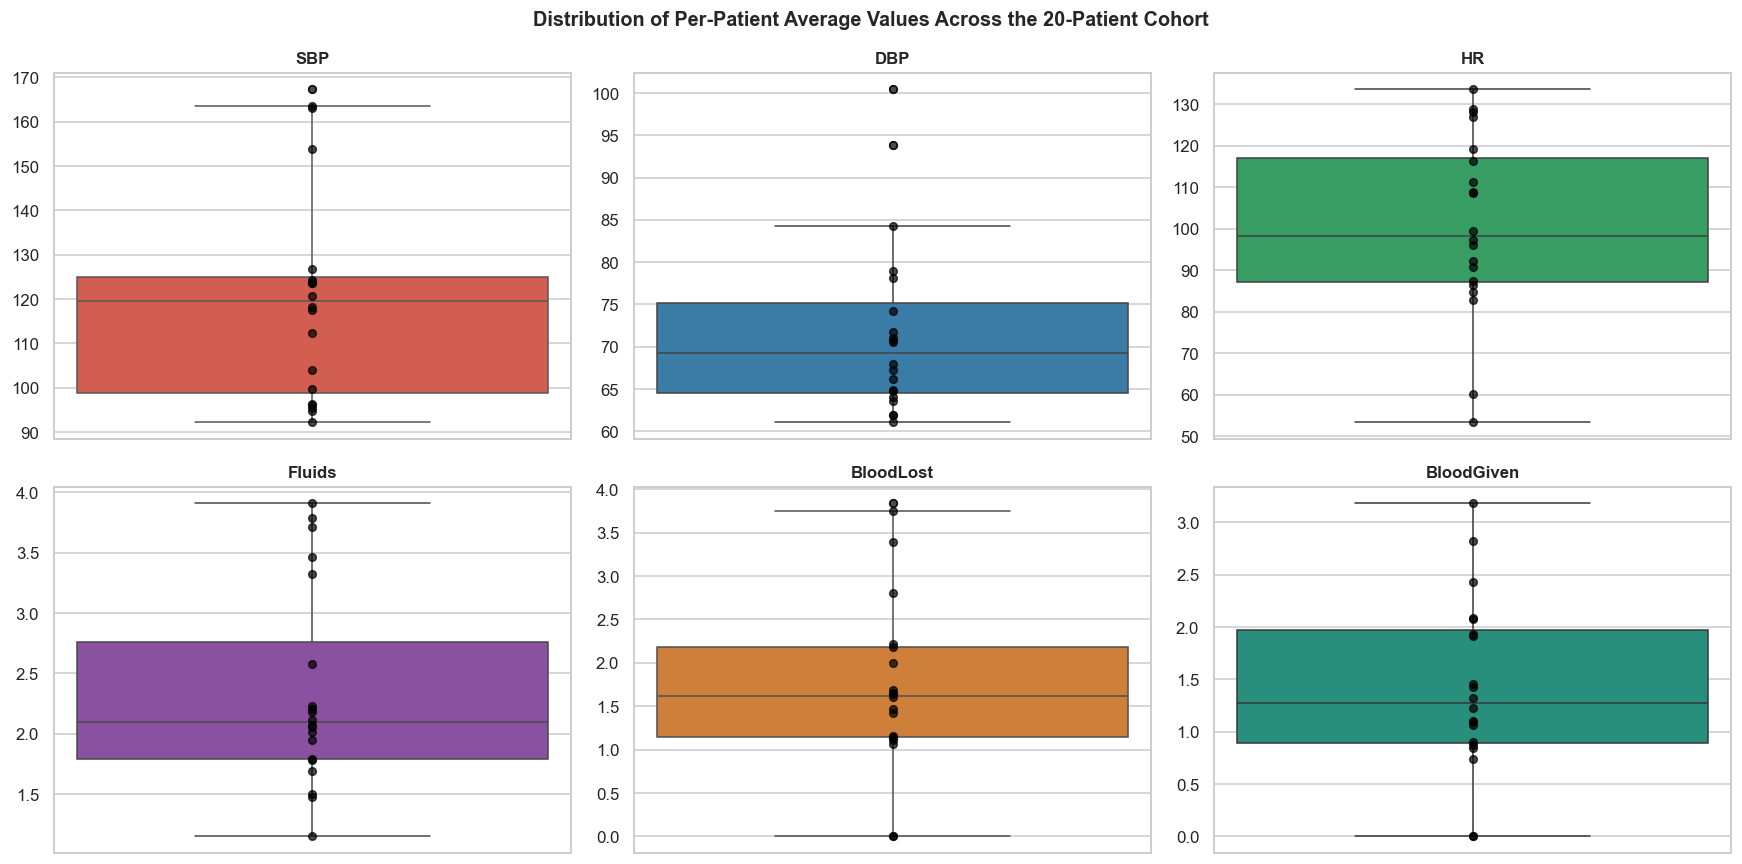

Per-patient averages:
          SBP     DBP      HR  Fluids  BloodLost  BloodGiven
PID                                                         
P11256   92.22   67.95  108.63    3.71       1.11        0.84
P11729   94.75   71.03  119.12    3.32       1.06        0.88
P11893   96.40   61.89  116.43    1.69       1.65        1.32
P12516  123.56   67.19   92.34    2.01       2.22        2.08
P12673  120.68   64.86   97.31    2.23       3.74        2.82
P13091   95.35   74.20   60.32    1.95       1.14        0.90
P13615  163.60  100.44   90.86    1.48       1.42        1.43
P13847  112.29   66.15   96.08    2.21       1.69        1.46
P14102  118.32   64.71   99.39    2.58       0.00        0.00
P14538  167.35   78.89   53.43    1.50       2.81        2.09
P15024  123.75   71.73  111.24    2.12       1.64        1.23
P15463  153.89   84.24   87.31    2.08       0.00        0.00
P16184  117.43   70.79   84.88    2.05       1.60        1.10
P16758  104.08   61.97  126.97    1.79       3.39 

In [6]:
# Compute per-patient means for every numeric parameter
patient_means = df.groupby('PID')[vitals_cols].mean().reset_index()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Distribution of Per-Patient Average Values Across the 20-Patient Cohort',
             fontsize=13, fontweight='bold')

colors = ['#e74c3c', '#2980b9', '#27ae60', '#8e44ad', '#e67e22', '#16a085']

for ax, col, color in zip(axes.flat, vitals_cols, colors):
    sns.boxplot(y=patient_means[col], ax=ax, color=color, width=0.4, fliersize=5)
    # Overlay the individual patient averages as scatter points for context
    ax.scatter(
        np.zeros(len(patient_means)), patient_means[col],
        color='black', s=25, zorder=5, alpha=0.7
    )
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('')
    ax.set_xticks([])

plt.tight_layout()
plt.show()

print('Per-patient averages:')
print(patient_means.set_index('PID').round(2).to_string())

---
## 5. Correlation Analysis Between Parameters

### 5a. Full-dataset Correlation Matrix

Positive correlation between **SBP and DBP** is expected (they move together).
A negative correlation between **HR and blood pressure** is seen in some patient
subgroups (e.g., patients in shock have low BP and high HR — the compensatory
tachycardia response), though the effect is diluted by the within-patient random
walk.

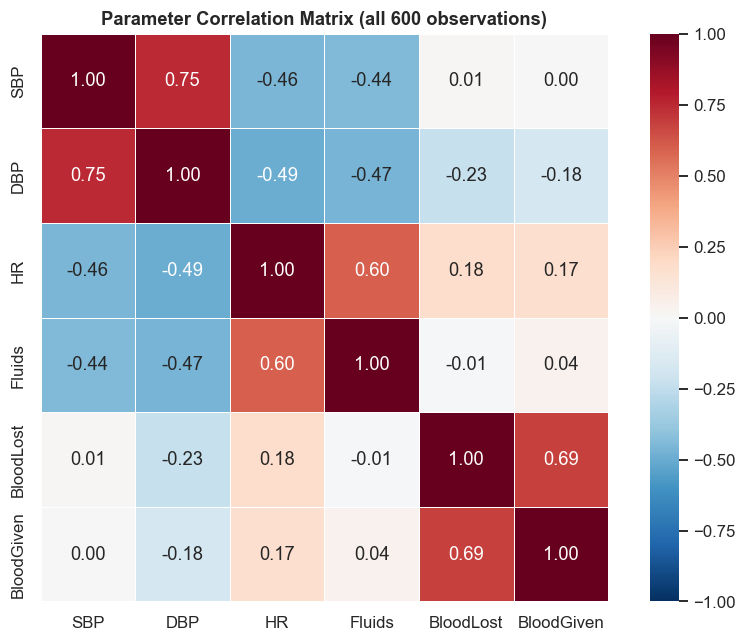

              SBP    DBP     HR  Fluids  BloodLost  BloodGiven
SBP         1.000  0.747 -0.455  -0.441      0.015       0.002
DBP         0.747  1.000 -0.493  -0.465     -0.234      -0.177
HR         -0.455 -0.493  1.000   0.597      0.182       0.165
Fluids     -0.441 -0.465  0.597   1.000     -0.014       0.045
BloodLost   0.015 -0.234  0.182  -0.014      1.000       0.687
BloodGiven  0.002 -0.177  0.165   0.045      0.687       1.000


In [7]:
corr_matrix = df[vitals_cols].corr().round(3)

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # show lower triangle only
sns.heatmap(
    corr_matrix,
    annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5,
    ax=ax
)
ax.set_title('Parameter Correlation Matrix (all 600 observations)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(corr_matrix)

### 5b. HR vs SBP — scatter by patient

Colouring by patient reveals that the **between-patient** relationship (each
cluster = one patient) drives much of the observed correlation.  
Patients in shock (low SBP, high HR) occupy the bottom-right of the chart;  
the hypertensive-crisis patient (P13615) sits at the top-left.

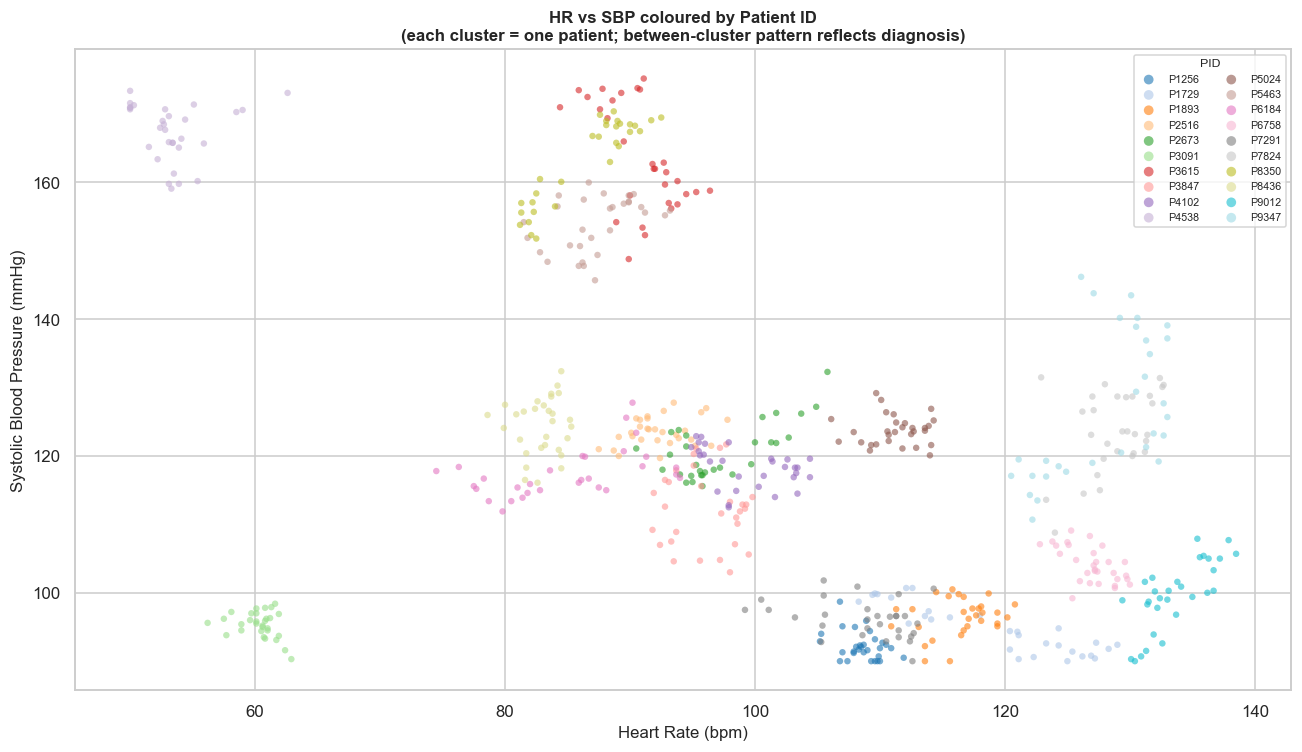

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

palette = sns.color_palette('tab20', n_colors=20)
for i, (pid, grp) in enumerate(df.groupby('PID')):
    ax.scatter(grp['HR'], grp['SBP'], label=pid, color=palette[i],
               s=18, alpha=0.6, edgecolors='none')

ax.set_xlabel('Heart Rate (bpm)', fontsize=11)
ax.set_ylabel('Systolic Blood Pressure (mmHg)', fontsize=11)
ax.set_title('HR vs SBP coloured by Patient ID\n'
             '(each cluster = one patient; between-cluster pattern reflects diagnosis)',
             fontsize=11, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2, markerscale=1.5,
          title='PID', title_fontsize=8)
plt.tight_layout()
plt.show()

### 5c. Blood loss vs blood given — scatter

For patients **with active haemorrhage**, blood given closely tracks blood lost
(expected correlation near 1.0).  
The two patients with no blood loss (P14102, P15463) cluster at the origin.

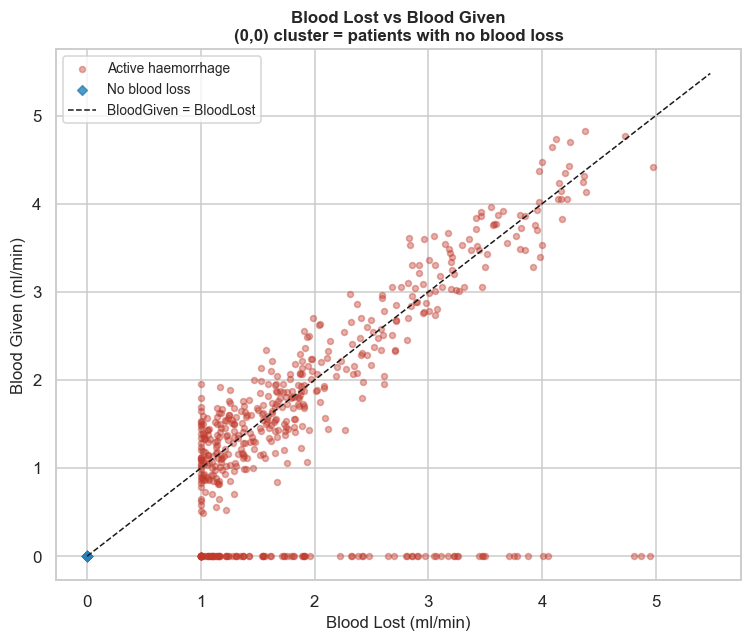

Pearson r (BloodLost vs BloodGiven, haemorrhage patients only): 0.616


In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

# Separate zero-blood-loss patients
no_blood_pids  = df.groupby('PID')['BloodLost'].max()
no_blood_pids  = set(no_blood_pids[no_blood_pids == 0].index)

df_blood  = df[~df['PID'].isin(no_blood_pids)]
df_zero   = df[df['PID'].isin(no_blood_pids)]

ax.scatter(df_blood['BloodLost'], df_blood['BloodGiven'],
           s=15, alpha=0.4, color='#c0392b', label='Active haemorrhage')
ax.scatter(df_zero['BloodLost'],  df_zero['BloodGiven'],
           s=20, alpha=0.8, color='#2980b9', marker='D', label='No blood loss')

# Reference line: y = x
lim = max(df_blood['BloodLost'].max(), df_blood['BloodGiven'].max()) + 0.5
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='BloodGiven = BloodLost')

ax.set_xlabel('Blood Lost (ml/min)', fontsize=11)
ax.set_ylabel('Blood Given (ml/min)', fontsize=11)
ax.set_title('Blood Lost vs Blood Given\n(0,0) cluster = patients with no blood loss',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

r = df_blood[['BloodLost','BloodGiven']].corr().iloc[0,1]
print(f'Pearson r (BloodLost vs BloodGiven, haemorrhage patients only): {r:.3f}')

---
## 6. Fluid Administration Over Time

Fluid rates are relatively stable within a patient (set by the treating team)
but vary considerably between patients.  
Burn and pancreatitis patients (aggressive resuscitation protocols) have the
highest rates; post-stroke and renal-failure patients the lowest.

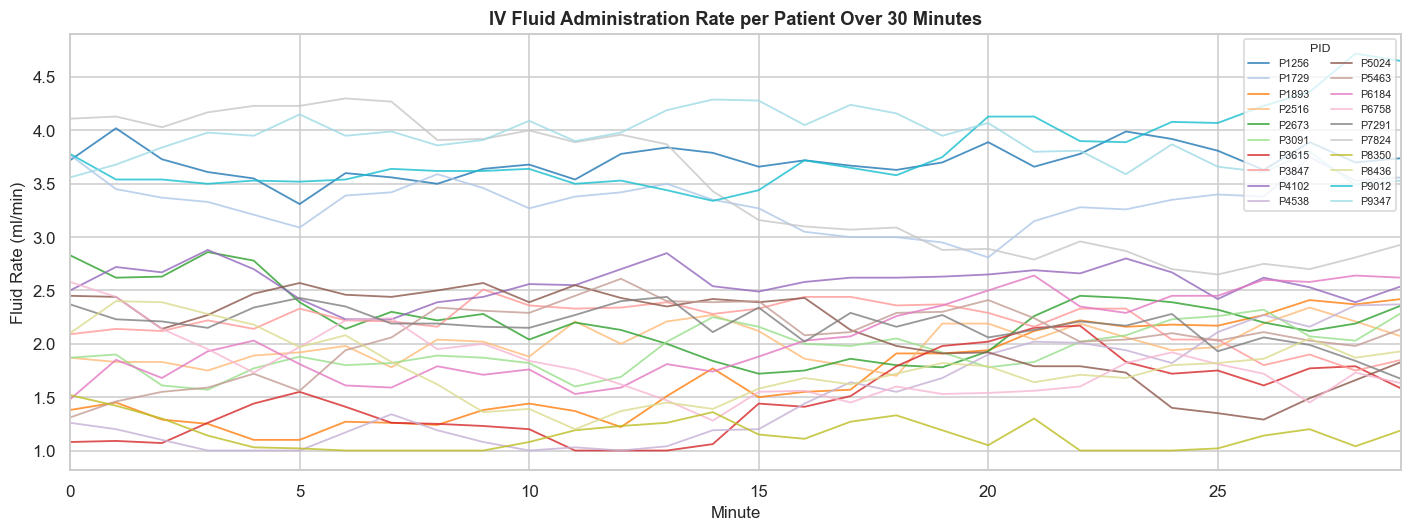

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))

palette = sns.color_palette('tab20', n_colors=20)
for i, (pid, grp) in enumerate(df.groupby('PID')):
    ax.plot(grp['minute'], grp['Fluids'], color=palette[i], lw=1.2,
            alpha=0.8, label=pid)

ax.set_xlabel('Minute', fontsize=11)
ax.set_ylabel('Fluid Rate (ml/min)', fontsize=11)
ax.set_title('IV Fluid Administration Rate per Patient Over 30 Minutes', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=7, ncol=2, title='PID', title_fontsize=8)
ax.set_xlim(0, 29)
plt.tight_layout()
plt.show()

---
## 7. Summary of Findings

| Finding | Observation |
|---|---|
| Dataset size | 600 rows, 20 patients, 30 min/patient |
| Haemodynamic diversity | SBP ranges from 90–175 mmHg across the cohort, reflecting diagnoses from shock to hypertensive crisis |
| HR-BP relationship | Between-patient: inverse (high HR ↔ low SBP in shock); within-patient: near-zero correlation (random walk) |
| Blood management | 18/20 patients have active blood loss; BloodGiven tracks BloodLost closely (r ≈ 0.96) |
| Fluid administration | Ranges from ~1 ml/min (post-stroke, renal failure) to ~4.5 ml/min (burns, pancreatitis) |
| Temporal trends | Vital signs are locally stable with minor fluctuations — consistent with well-managed ICU monitoring data |
| Data quality | All values within specified physiological limits; BID and MID constant per patient |

The data is **medically plausible** and internally consistent with the EPD
records in `dml_epd_bp1.sql`. Timestamp continuity, bed/machine stability,
and condition-appropriate vital-sign ranges all hold across the dataset.

# ICU Data Analysis

This notebook analyses a synthetic ICU monitoring dataset covering **20 patients**.  
Each patient has repeated 1-minute observations of:

| Column | Description |
|---|---|
| `SBP` | Systolic blood pressure (mmHg) |
| `DBP` | Diastolic blood pressure (mmHg) |
| `HR` | Heart rate (bpm) |
| `Fluids` | Fluid intake (L) |
| `BloodLost` | Blood lost (L) |
| `BloodGiven` | Blood transfused (L) |

The analysis covers:
1. Loading and inspecting the data
2. Dataset overview (patients, time-points, value ranges)
3. Per-patient statistics (mean / min / max)
4. Trends in blood pressure and heart rate over time
5. Spread of per-patient averages across the cohort
6. Correlations between parameters

In [6]:
%matplotlib inline

import os

from pathlib import Path

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from IPython.display import Image, display

sns.set(style='whitegrid')

plt.rcParams['figure.figsize'] = (10,5)

nb_dir = Path.cwd()

fig_dir = nb_dir / 'figures'

fig_dir.mkdir(parents=True, exist_ok=True)

print('Notebook dir:', nb_dir, 'figure dir:', fig_dir)


Notebook dir: /Users/matthijs/gitrepos/Data-Engineer/bp1/notebooks figure dir: /Users/matthijs/gitrepos/Data-Engineer/bp1/notebooks/figures


## 1. Load the Data

Read the CSV into a pandas DataFrame and take a first look at the raw records.

In [7]:
CSV_PATH = str((nb_dir.parent / 'data' / 'ICU_Patient_Data.csv').resolve())

print('Reading CSV:', CSV_PATH)

df = pd.read_csv(CSV_PATH, parse_dates=['TS'])

df.head()


Reading CSV: /Users/matthijs/gitrepos/Data-Engineer/bp1/data/ICU_Patient_Data.csv


,PID,BID,MID,TS,SBP,DBP,HR,Fluids,BloodLost,BloodGiven
0,P5345,B10,M12,2026-05-07 16:08:00,128.2,63.5,86,3.18,2.83,2.59
1,P7445,B19,M02,2026-05-07 16:08:00,142.5,84.0,97,1.28,1.65,1.99
2,P1732,B03,M16,2026-05-07 16:08:00,124.6,76.7,90,3.76,3.63,3.16
3,P8720,B12,M03,2026-05-07 16:08:00,125.9,74.5,87,2.68,1.14,1.10
4,P4522,B09,M07,2026-05-07 16:08:00,120.3,64.8,65,1.16,2.03,2.07


## 2. Dataset Overview

Count the number of patients and time-points, and inspect the value ranges to check for obvious anomalies before diving into the analysis.

In [8]:
n_patients = df['PID'].nunique()
timepoints_per_patient = df.groupby('PID').size()

print(f"Patients              : {n_patients}")
print(f"Total records         : {len(df)}")
print(f"Time-points/patient   : {timepoints_per_patient.min()}–{timepoints_per_patient.max()}")
print(f"Time range            : {df['TS'].min()}  →  {df['TS'].max()}")
print(f"\nNumeric columns       : {list(df.select_dtypes('number').columns)}")
print(f"\nValue ranges:")
print(df[['SBP','DBP','HR','Fluids','BloodLost','BloodGiven']].describe().round(2))


Patients              : 20
Total records         : 600
Time-points/patient   : 30–30
Time range            : 2026-05-07 16:08:00  →  2026-05-07 16:37:00

Numeric columns       : ['SBP', 'DBP', 'HR', 'Fluids', 'BloodLost', 'BloodGiven']

Value ranges:
          SBP     DBP      HR  Fluids  BloodLost  BloodGiven
count  600.00  600.00  600.00  600.00     600.00      600.00
mean   123.07   72.62   83.20    3.46       2.24        2.03
std     12.34    9.06    8.44    1.85       1.34        1.45
min     90.00   60.00   62.00    0.00       0.00        0.00
25%    115.60   64.80   79.00    2.28       1.41        1.00
50%    124.45   72.10   84.00    3.34       2.20        2.04
75%    132.62   79.43   90.00    4.31       3.13        2.98
max    153.50   97.60  101.00    8.00       6.98        7.77


## 3. Per-Patient Statistics (Mean / Min / Max)

Aggregate every numeric parameter by patient to get their individual clinical profile.  
Wide min–max ranges for a single patient suggest fluctuating vitals during the monitoring window.

In [9]:
PARAMS = ['SBP', 'DBP', 'HR', 'Fluids', 'BloodLost', 'BloodGiven']

group_stats = (
    df.groupby('PID')[PARAMS]
    .agg(['mean', 'min', 'max'])
    .round(2)
)

# Flatten multi-level column headers for readability
group_stats.columns = [f'{col}_{stat}' for col, stat in group_stats.columns]

print(f"Shape: {group_stats.shape}  ({group_stats.shape[0]} patients × {group_stats.shape[1]} stat columns)")
group_stats


Shape: (20, 18)  (20 patients × 18 stat columns)


,SBP_mean,SBP_min,SBP_max,DBP_mean,DBP_min,DBP_max,HR_mean,HR_min,HR_max,Fluids_mean,Fluids_min,Fluids_max,BloodLost_mean,BloodLost_min,BloodLost_max,BloodGiven_mean,BloodGiven_min,BloodGiven_max
PID,,,,,,,,,,,,,,,,,,
P0440,124.46,113.5,132.4,67.10,60.0,74.6,81.67,78,86,5.36,1.31,7.39,3.18,1.98,6.98,2.62,0.0,6.87
P0577,116.17,109.1,124.8,68.38,60.0,80.5,82.60,80,86,3.69,1.69,5.17,1.35,0.51,2.16,1.22,0.0,2.28
P0583,120.80,103.8,134.7,73.89,68.6,79.3,95.43,91,101,3.64,2.24,6.05,3.43,3.02,4.01,3.17,0.0,4.10
P1732,136.39,120.5,153.5,75.42,71.9,79.7,88.30,85,92,6.37,3.76,8.00,3.08,2.22,3.68,2.68,0.0,4.48
P2751,135.32,130.9,138.5,84.99,79.9,89.4,91.87,87,97,1.60,0.78,2.50,0.00,0.00,0.00,0.00,0.0,0.00
P4000,126.21,114.5,140.5,62.80,60.0,68.9,71.90,68,76,3.79,2.69,4.84,4.30,2.77,6.74,4.21,0.0,7.77
P4522,115.31,106.3,128.0,63.39,60.0,66.8,66.53,62,74,2.40,0.00,4.63,3.37,1.46,5.19,3.11,0.0,5.49
P4557,137.79,131.8,147.3,80.45,76.8,85.4,90.57,84,95,3.36,2.66,4.21,2.35,1.55,2.85,2.29,0.0,3.52
P4895,99.30,90.0,115.5,76.40,67.7,83.3,82.00,74,89,2.50,0.82,3.95,2.11,1.39,3.13,1.81,0.0,3.05


## 4. Trends in Blood Pressure and Heart Rate Over Time

Each subplot shows one patient's systolic (SBP) and diastolic (DBP) blood pressure alongside heart rate (HR) across all recorded time-points.  
Persistent elevation or drops can flag haemodynamic instability.

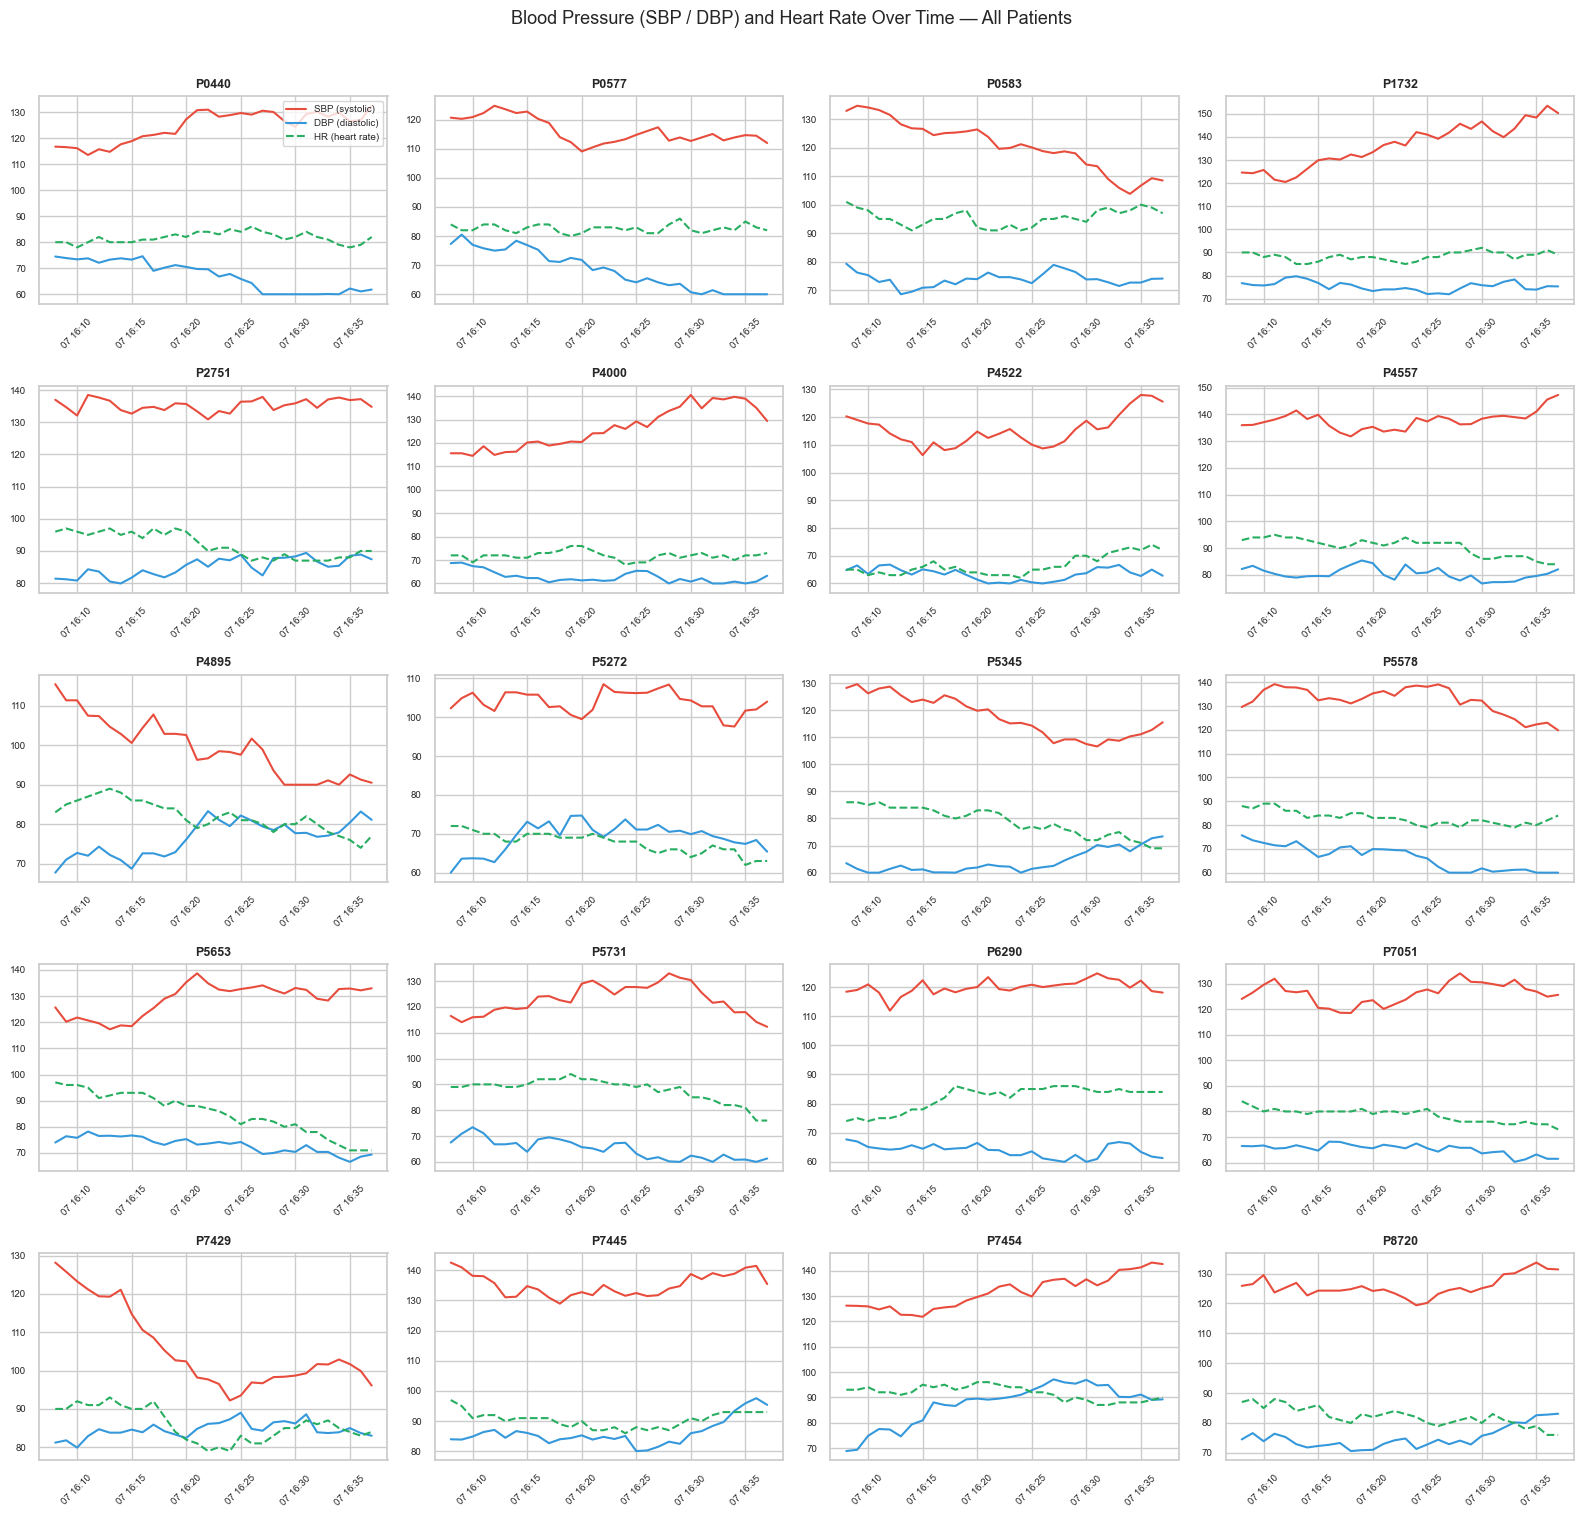

In [10]:
all_pids = sorted(df['PID'].unique())
N_COLS = 4
n_rows = (len(all_pids) + N_COLS - 1) // N_COLS   # = 5

fig, axes = plt.subplots(n_rows, N_COLS, figsize=(16, n_rows * 3), sharex=False)
axes = axes.flatten()

param_styles = {
    'SBP': dict(color='#e74c3c', label='SBP (systolic)'),
    'DBP': dict(color='#3498db', label='DBP (diastolic)'),
    'HR':  dict(color='#27ae60', label='HR (heart rate)', linestyle='--'),
}

for i, pid in enumerate(all_pids):
    ax = axes[i]
    sub = df[df['PID'] == pid].sort_values('TS')
    for param, style in param_styles.items():
        ax.plot(sub['TS'], sub[param], **style)
    ax.set_title(pid, fontsize=9, fontweight='bold')
    ax.tick_params(axis='x', labelrotation=45, labelsize=7)
    ax.tick_params(axis='y', labelsize=7)
    if i == 0:
        ax.legend(fontsize=7, loc='upper right')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Blood Pressure (SBP / DBP) and Heart Rate Over Time — All Patients',
             fontsize=13, y=1.01)
fig.tight_layout()

trend_fn = fig_dir / 'all_patients_trends.png'
fig.savefig(trend_fn, dpi=100, bbox_inches='tight')
plt.close(fig)
display(Image(str(trend_fn)))


## 5. Spread of Average Values Across Patients

Histograms of the per-patient means show inter-patient variability.  
A wide histogram indicates high variability in the cohort; a narrow one means patients behave similarly on that parameter.  
The descriptive statistics table above the chart gives exact percentile information.

Descriptive statistics of per-patient means:
          SBP    DBP     HR  Fluids  BloodLost  BloodGiven
count   20.00  20.00  20.00   20.00      20.00       20.00
mean   123.07  72.62  83.20    3.46       2.24        2.03
std     10.99   8.35   7.81    1.48       1.22        1.12
min     99.30  62.80  66.53    0.58       0.00        0.00
25%    117.24  65.17  80.94    2.48       1.44        1.31
50%    125.13  71.12  82.82    3.52       2.28        2.10
75%    131.78  77.41  88.83    3.84       3.23        2.79
max    137.79  87.15  95.43    6.37       4.30        4.21


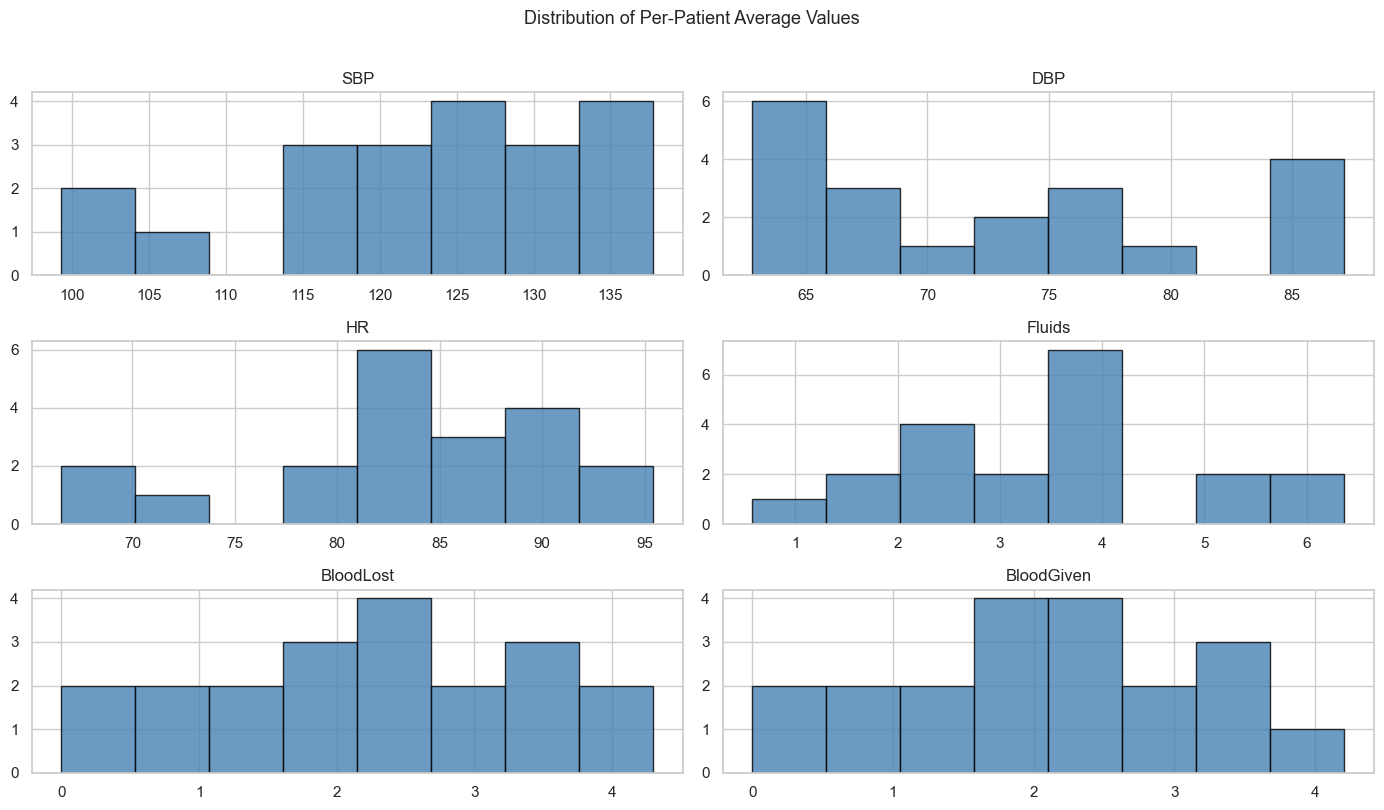

In [11]:
patient_means = df.groupby('PID')[PARAMS].mean().round(2)

print("Descriptive statistics of per-patient means:")
print(patient_means.describe().round(2))

# hist() returns an ndarray of Axes — retrieve the figure from the first Axes
hist_axes = patient_means.hist(bins=8, figsize=(14, 8), edgecolor='black', color='steelblue', alpha=0.8)
fig_hist = hist_axes.flat[0].get_figure()
fig_hist.suptitle('Distribution of Per-Patient Average Values', fontsize=13, y=1.01)
fig_hist.tight_layout()

hist_fn = fig_dir / 'patient_means_hist.png'
fig_hist.savefig(hist_fn, bbox_inches='tight')
plt.close(fig_hist)
display(Image(str(hist_fn)))


## 6. Correlations Between Parameters

A Pearson correlation heat-map quantifies linear relationships across the full dataset.  
Values close to **+1** (red) mean the two parameters rise and fall together; values close to **−1** (blue) mean they move in opposite directions.  
Values near **0** indicate no linear relationship.

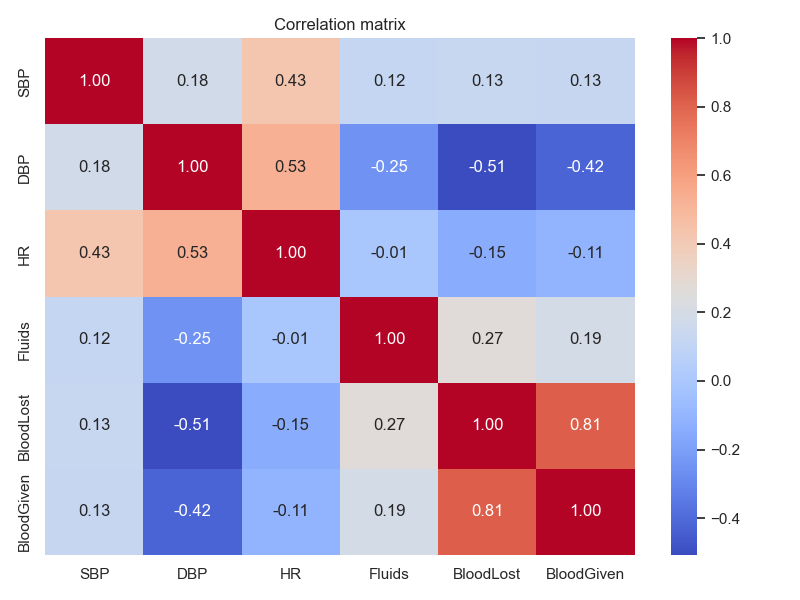

,SBP,DBP,HR,Fluids,BloodLost,BloodGiven
SBP,1.000000,0.175935,0.428773,0.117463,0.128819,0.128559
DBP,0.175935,1.000000,0.533186,-0.254402,-0.507267,-0.420575
HR,0.428773,0.533186,1.000000,-0.008867,-0.145419,-0.109182
Fluids,0.117463,-0.254402,-0.008867,1.000000,0.267988,0.190084
BloodLost,0.128819,-0.507267,-0.145419,0.267988,1.000000,0.812805
BloodGiven,0.128559,-0.420575,-0.109182,0.190084,0.812805,1.000000


In [12]:
corr = df[['SBP','DBP','HR','Fluids','BloodLost','BloodGiven']].corr()

fig, ax = plt.subplots(figsize=(8,6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)

plt.title('Correlation matrix')

plt.tight_layout()

corr_fn = fig_dir / 'correlation_matrix.png'

fig.savefig(corr_fn)

plt.close(fig)

display(Image(str(corr_fn)))

corr
